In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
df = pd.read_csv("advertising.csv")


In [4]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [5]:
df.shape

(200, 4)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [7]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


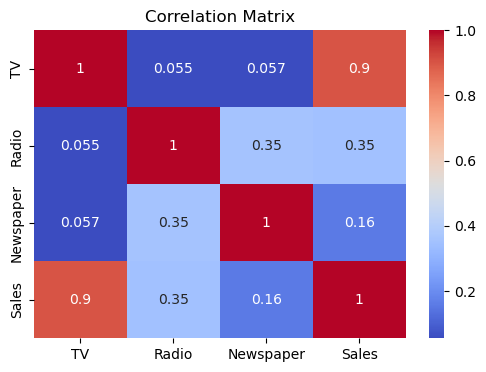

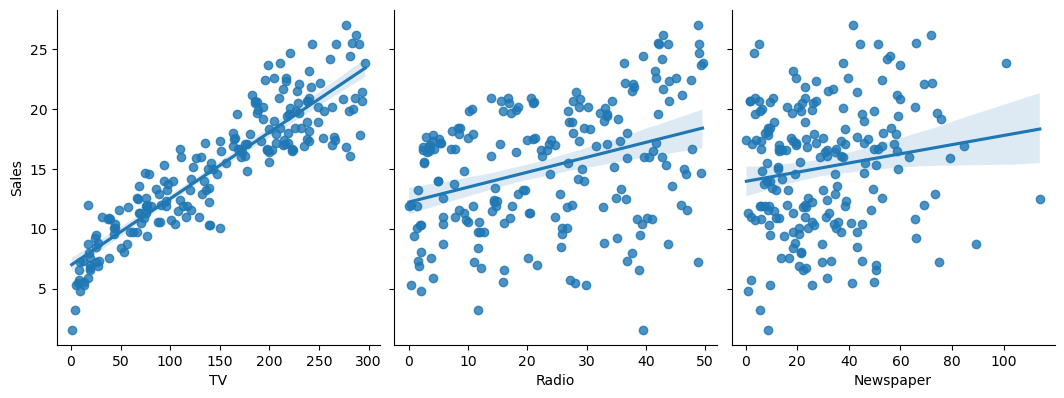

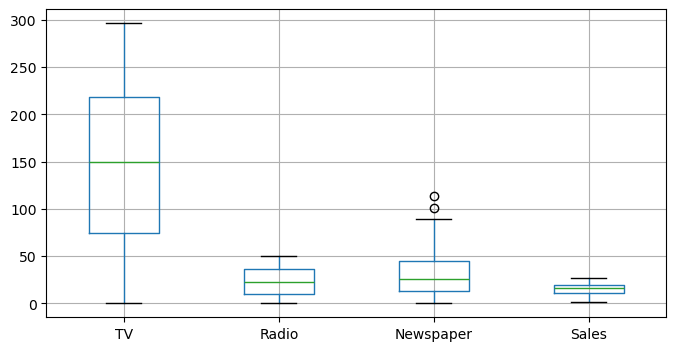

In [10]:
# Correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Relationship of each channel with Sales
sns.pairplot(df, x_vars=["TV", "Radio", "Newspaper"], y_vars="Sales",
             height=4, aspect=0.9, kind="reg")
plt.show()

# Check for outliers
df.boxplot(figsize=(8, 4))
plt.show()

In [11]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(160, 3) (40, 3)


In [12]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
def evaluate(name, model):
    pred = model.predict(X_test)
    print(f"--- {name} ---")
    print("R²  :", round(r2_score(y_test, pred), 4))
    print("MAE :", round(mean_absolute_error(y_test, pred), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 4))
    print("CV R² (5-fold):", round(cross_val_score(model, X, y, cv=5, scoring="r2").mean(), 4))
    print()

evaluate("Linear Regression", lin_reg)
evaluate("Random Forest", rf)

--- Linear Regression ---
R²  : 0.9059
MAE : 1.2748
RMSE: 1.7052
CV R² (5-fold): 0.8954

--- Random Forest ---
R²  : 0.9547
MAE : 0.9141
RMSE: 1.1828
CV R² (5-fold): 0.9428



TV           0.054509
Radio        0.100945
Newspaper    0.004337
dtype: float64
Intercept: 4.714126402214131


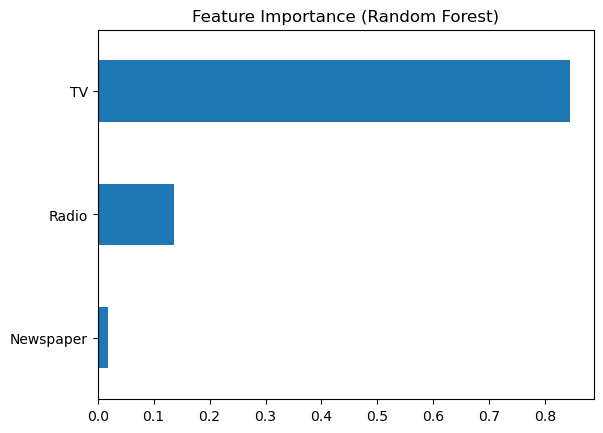

In [14]:
# Linear regression coefficients
coef = pd.Series(lin_reg.coef_, index=X.columns)
print(coef)
print("Intercept:", lin_reg.intercept_)

# Random forest feature importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Feature Importance (Random Forest)")
plt.show()

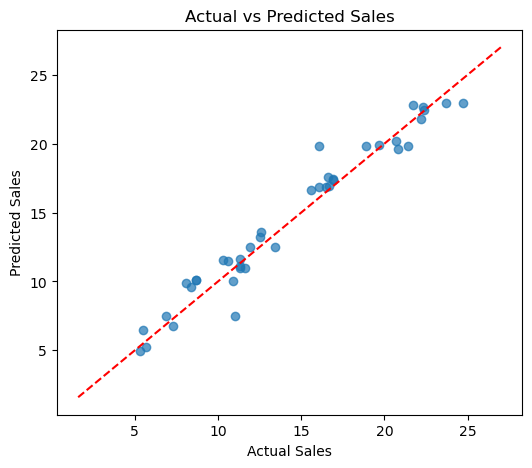

In [15]:

y_pred = rf.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()